# First look: demand, temperature and correlations

A thin notebook over `spain_electricity.views`: every number is computed in Spark from `data/processed/hourly_features`; this notebook only draws the two charts.

Prerequisite: `uv run python scripts/download_history.py --start ... --end ...` and `uv run python scripts/ingest.py`.

In [1]:
import matplotlib.pyplot as plt

from spain_electricity import views
from spain_electricity.config import DataPaths
from spain_electricity.spark_session import get_spark

spark = get_spark("notebook")
paths = DataPaths.from_env()
WEEKDAY_COLOR, WEEKEND_COLOR = "#2a78d6", "#eb6834"  # validated categorical slots 1 and 2
views.data_status(spark, paths)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/12 16:43:24 WARN Utils: Your hostname, Manuels-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.135 instead (on interface en0)
26/11/12 16:43:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 16:43:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/12 16:43:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


,dataset,rows,first,last
0,generation,616032,2020-12-31 23:00:00,2026-11-09 22:55:00
1,demand_forecast,616141,2020-12-31 23:00:00,2026-11-11 01:55:00
2,market_price,148105,2020-12-31 23:00:00,2026-11-11 22:45:00
3,weather,256800,2021-01-01 00:00:00,2026-11-10 23:00:00
4,gas_price,2140,2021-01-02 00:00:00,2026-11-11 00:00:00
5,hourly_features,51336,2020-12-31 23:00:00,2026-11-09 22:00:00


## Daily demand vs national temperature

We expect a U shape: demand rises on the coldest days (heating) and on the hottest ones (cooling). With a single sample month only one arm of the U can show; the full history is needed to see both.

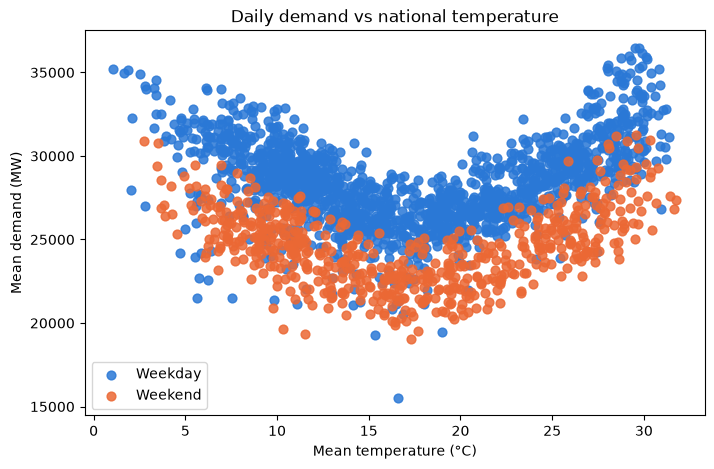

In [2]:
daily = views.daily_demand_vs_temperature(spark, paths).dropna()
fig, ax = plt.subplots(figsize=(8, 5))
for is_weekend, label, color in ((False, "Weekday", WEEKDAY_COLOR), (True, "Weekend", WEEKEND_COLOR)):
    days = daily[daily["is_weekend"] == is_weekend]
    ax.scatter(days["temperature_c"], days["demand_mw"], s=40, color=color, label=label, alpha=0.85)
ax.set_title("Daily demand vs national temperature")
ax.set_xlabel("Mean temperature (°C)")
ax.set_ylabel("Mean demand (MW)")
ax.legend()
plt.show()

## Correlations between hourly variables

Pearson correlation computed with `pyspark.ml.stat.Correlation`. Correlation is not causation: it only says which variables move together.

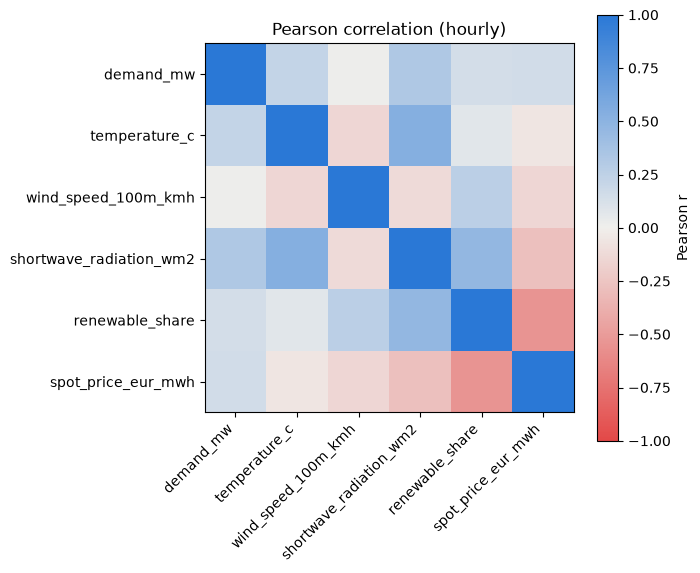

In [3]:
from matplotlib.colors import LinearSegmentedColormap

columns = [
    "demand_mw",
    "temperature_c",
    "wind_speed_100m_kmh",
    "shortwave_radiation_wm2",
    "renewable_share",
    "spot_price_eur_mwh",
]
matrix = views.correlation_matrix(spark, paths, columns)
diverging = LinearSegmentedColormap.from_list("red_gray_blue", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrix.values, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
ax.set_yticks(range(len(columns)), columns)
ax.set_title("Pearson correlation (hourly)")
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()